# A first EM algorithm

## When EM applies

EM applies when two easy problems depend on each other.

1. If the hidden variable $Z$ were known, estimating $\theta$ would be easy.
2. If $\theta$ were known, calculating $p(Z\mid X,\theta)$ would be easy.

EM solves them in turn.

1. **E step.** Use the current $\theta$ to calculate probabilities for $Z$.
2. **M step.** Use those probabilities to update $\theta$.

Then repeat. Each round raises or preserves the observed-data likelihood. The iteration converges to a stationary point, although the point can depend on the starting values.

This requires a joint model $p(X,Z\mid\theta)$ and E and M steps that we can compute.

## A two-group model

We observe $X_i$, but not its group $Z_i$. If the group labels were known, the group proportions and means would be simple counts and averages. EM calculates a probability for each label and uses those probabilities as weights.

Let $P(Z_i=1)=\pi$ and

$$X_i\mid Z_i=k\sim N(\mu_k,1),\qquad k\in\{0,1\}.$$

The unknown parameters are $\theta=(\pi,\mu_0,\mu_1)$.


## One fixed sample

We simulate one observed value from one of two hidden groups. The hidden label is shown because this is a teaching example. In real data, it is unknown. The observed value could, for example, be an apple weight and the hidden label its variety.


In [1]:
library(hpgR)

set.seed(8149)

n_sample <- 80L
true_mean <- c(-1.5, 1.5)
sample_data <- simulateGaussianMixture(n_sample, true_mean)
hidden_group <- sample_data$group
observed <- sample_data$observed

data.frame(
  observed = round(observed[1:8], 2),
  hidden_group = hidden_group[1:8]
)


observed,hidden_group
<dbl>,<dbl>
-2.18,0
2.33,1
0.41,1
2.79,1
3.11,1
-1.85,0
1.86,1
-0.69,0


## E step: infer the hidden group

Given the current parameters, calculate the probability that observation $i$ came from group 1.

$$
r_i^{(t)}
=P(Z_i=1\mid X_i=x_i,\theta^{(t)})
=\frac{\pi^{(t)}\phi(x_i;\mu_1^{(t)},1)}
{(1-\pi^{(t)})\phi(x_i;\mu_0^{(t)},1)
+\pi^{(t)}\phi(x_i;\mu_1^{(t)},1)}.
$$

$r_i^{(t)}$ is also $E[Z_i\mid X_i,\theta^{(t)}]$. It is the expected group-1 count contributed by observation $i$.


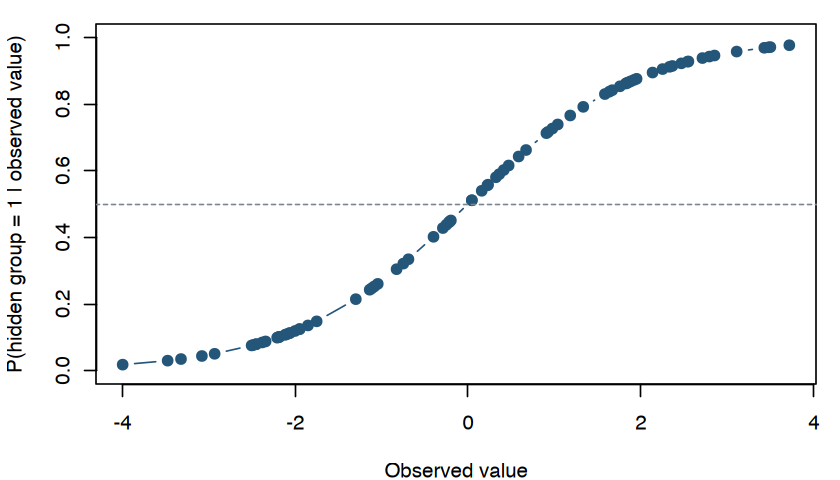

In [2]:
start <- list(pi = 0.5, mu = c(-0.5, 0.5))
r <- gaussianResponsibilities(observed, start$pi, start$mu)
ordered <- order(observed)

options(repr.plot.width = 7, repr.plot.height = 4)
par(mar = c(4, 4, 1, 1))
plot(
  observed[ordered], r[ordered], type = "b", pch = 19,
  xlab = "Observed value",
  ylab = "P(hidden group = 1 | observed value)",
  ylim = c(0, 1), col = "#24567a"
)
abline(h = 0.5, lty = 2, col = "#7a8793")


A responsibility is not a hard group label. It measures uncertainty about the hidden group. Values near $1/2$ mean that the two groups remain difficult to distinguish.


## M step: update the parameters

Use the responsibilities as fractional group labels.

$$
\pi^{(t+1)}=\frac{1}{n}\sum_i r_i^{(t)},
$$

$$
\mu_0^{(t+1)}=\frac{\sum_i(1-r_i^{(t)})x_i}{\sum_i(1-r_i^{(t)})},\qquad
\mu_1^{(t+1)}=\frac{\sum_i r_i^{(t)}x_i}{\sum_i r_i^{(t)}}.
$$

In general, the M step maximizes the expected complete-data log likelihood.

$$
\theta^{(t+1)}=\arg\max_{\theta}
E_{Z\mid X,\theta^{(t)}}\left[\ell_c(\theta;X,Z)\right].
$$


In [3]:
fit <- fitGaussianMixture(observed, start)


## Why the iteration works

The observed-data log likelihood contains a sum over the hidden variable.

$$
\ell(\theta;X)=\log\sum_Z p(X,Z\mid\theta).
$$

After the E step, let $q_t(Z)=p(Z\mid X,\theta^{(t)})$. This distribution gives every possible hidden assignment a weight. With these weights fixed, EM uses the bound

$$
\mathcal F(q_t,\theta)
=E_{q_t}[\log p(X,Z\mid\theta)]+H(q_t)
\leq \ell(\theta;X).
$$

$H(q_t)=-E_{q_t}[\log q_t(Z)]$ measures the remaining uncertainty about the hidden assignment. It is constant during the M step. The bound touches the observed-data log likelihood at the current parameters. The M step raises the bound, and the new likelihood lies above the new bound.

$$
\ell(\theta^{(t+1)};X)
\geq \mathcal F(q_t,\theta^{(t+1)})
\geq \mathcal F(q_t,\theta^{(t)})
=\ell(\theta^{(t)};X).
$$

Any valid initial value can start the iteration. Under the usual regularity conditions, the likelihood converges and the parameter estimates approach a stationary point. Different initial values can reach different stationary points, so a useful starting value can still matter.


parameter,true_value,estimate
<chr>,<dbl>,<dbl>
pi,0.5,0.523
mu_0,-1.5,-1.726
mu_1,1.5,1.633


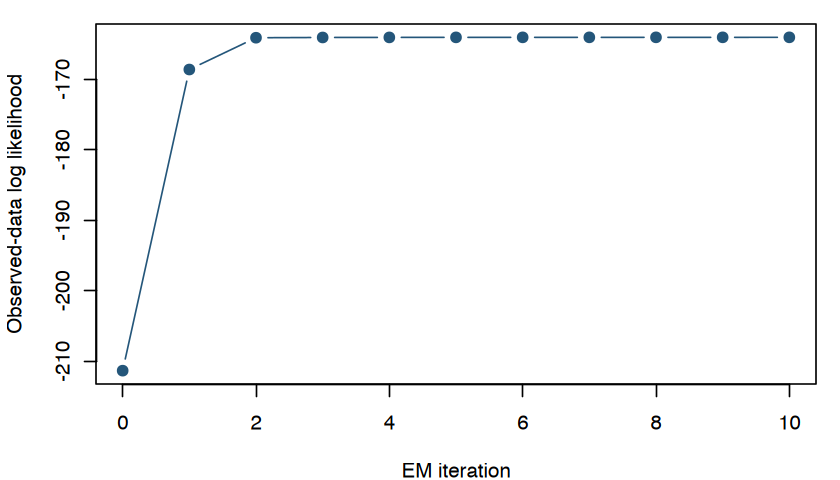

In [4]:
data.frame(
  parameter = c("pi", "mu_0", "mu_1"),
  true_value = c(0.5, true_mean),
  estimate = round(c(fit$pi, fit$mu), 3)
)

stopifnot(all(diff(fit$history$loglik) >= -1e-10))

shown <- fit$history[fit$history$iteration <= 10, ]
options(repr.plot.width = 7, repr.plot.height = 4)
par(mar = c(4, 4, 1, 1))
plot(
  shown$iteration, shown$loglik,
  type = "b", pch = 19, col = "#24567a",
  xlab = "EM iteration", ylab = "Observed-data log likelihood"
)


## What to remember

1. EM applies when hidden data would make estimation simple and both the E and M steps can be computed.
2. The **E step** turns each hidden value into a probability. The **M step** uses those probabilities as fractional observations.
3. Each iteration raises or preserves the observed-data likelihood, but different starting values can lead to different stationary points.

The [genotyping-error model](P8149_Lecture_2_MAF_MLE_EM.ipynb) uses the same structure. The latent variable is the true genotype, and the observed data are uncertain genotype measurements.
